# Lab 05 — Segmentación de clientes de Olist (RFM + K-Means)

Este notebook aplica `src/analytics/segment.py` sobre los datos reales de Olist:

1. Construye la tabla RFM (Recencia, Frecuencia, Monto) por cliente.
2. Prueba k de 2 a 8: curva de inercia (codo), silhouette y Davies-Bouldin.
3. Entrena el pipeline final con el k elegido y justifica la elección.
4. Reduce a 2D con PCA y grafica los segmentos.
5. Perfila los segmentos y guarda el resultado en `data/processed/clientes_segmentados.csv`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA

from analytics import extract, segment, transform

# El notebook vive en notebooks/, los datos en la raíz del proyecto
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW = RAIZ / "data" / "raw"
DATA_PROCESSED = RAIZ / "data" / "processed"
SEMILLA = 42

## 1. Construir los pedidos y la tabla RFM

In [2]:
df = extract.construir_dataset_base(extract.cargar_olist(str(DATA_RAW)))
df = transform.agregar_features_fecha(df)

pedidos = df[["customer_unique_id", "order_purchase_timestamp", "precio_total"]].rename(
    columns={"precio_total": "monto_pedido"}
)
# Algunos pedidos (cancelados / no disponibles) no tienen ítems: sin monto no aportan al RFM
print(f"Pedidos sin monto descartados: {pedidos['monto_pedido'].isna().sum():,}")
pedidos = pedidos.dropna(subset=["monto_pedido"])

fecha_referencia = pedidos["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
rfm = segment.calcular_rfm(pedidos, fecha_referencia)
X = rfm[["recencia", "frecuencia", "monto"]]

print(f"Fecha de referencia: {fecha_referencia.date()}")
print(f"Clientes únicos: {len(rfm):,}")
rfm.describe().round(2)

[EXTRACT] orders: 99,441 filas x 8 columnas
[EXTRACT] items: 112,650 filas x 7 columnas
[EXTRACT] customers: 99,441 filas x 5 columnas
[EXTRACT] payments: 103,886 filas x 5 columnas
[EXTRACT] reviews: 99,224 filas x 7 columnas
Pedidos sin monto descartados: 775
Fecha de referencia: 2018-09-04
Clientes únicos: 95,420


,recencia,frecuencia,monto
count,95420.00,95420.00,95420.00
mean,243.60,1.03,142.44
std,153.16,0.21,217.66
min,1.00,1.00,0.85
25%,119.00,1.00,47.90
50%,224.00,1.00,89.90
75%,353.00,1.00,155.00
max,729.00,16.00,13440.00


In [3]:
# Distribución de la frecuencia (pregunta 9.3)
n_recurrentes = int((rfm["frecuencia"] > 1).sum())
print(f"Clientes con frecuencia > 1: {n_recurrentes:,} ({n_recurrentes / len(rfm):.2%})")
rfm["frecuencia"].value_counts().sort_index()

Clientes con frecuencia > 1: 2,913 (3.05%)


frecuencia
1     92507
2      2673
3       192
4        29
5         9
6         5
7         3
9         1
16        1
Name: count, dtype: int64

## 2. Probar k de 2 a 8

K-Means agrupa en el espacio **escalado** (primer paso del pipeline), así que las métricas se calculan sobre ese mismo espacio. Como silhouette compara cada punto contra todos los demás, sobre ~95 mil clientes sería muy lento: se calcula sobre una muestra aleatoria fija de 10.000 clientes (la misma para todos los k).

In [4]:
rng = np.random.default_rng(SEMILLA)
idx_muestra = rng.choice(len(X), size=min(10_000, len(X)), replace=False)

resultados = []
for k in range(2, 9):
    pipeline_k = segment.entrenar_pipeline_clustering(X, n_clusters=k, random_state=SEMILLA)
    etiquetas_k = pipeline_k.predict(X)
    X_escalado_k = pipeline_k.named_steps["escalador"].transform(X)
    metricas_k = segment.evaluar_clustering(X_escalado_k[idx_muestra], etiquetas_k[idx_muestra])
    resultados.append({"k": k, "inercia": pipeline_k.named_steps["modelo"].inertia_, **metricas_k})

tabla_k = pd.DataFrame(resultados).set_index("k")
tabla_k.round(3)

,inercia,silhouette,davies_bouldin
k,,,
2,206640.086,0.741,0.569
3,141377.551,0.464,0.756
4,94309.964,0.496,0.672
5,79307.521,0.422,0.750
6,64784.126,0.440,0.699
7,55227.254,0.442,0.723
8,49192.176,0.448,0.708


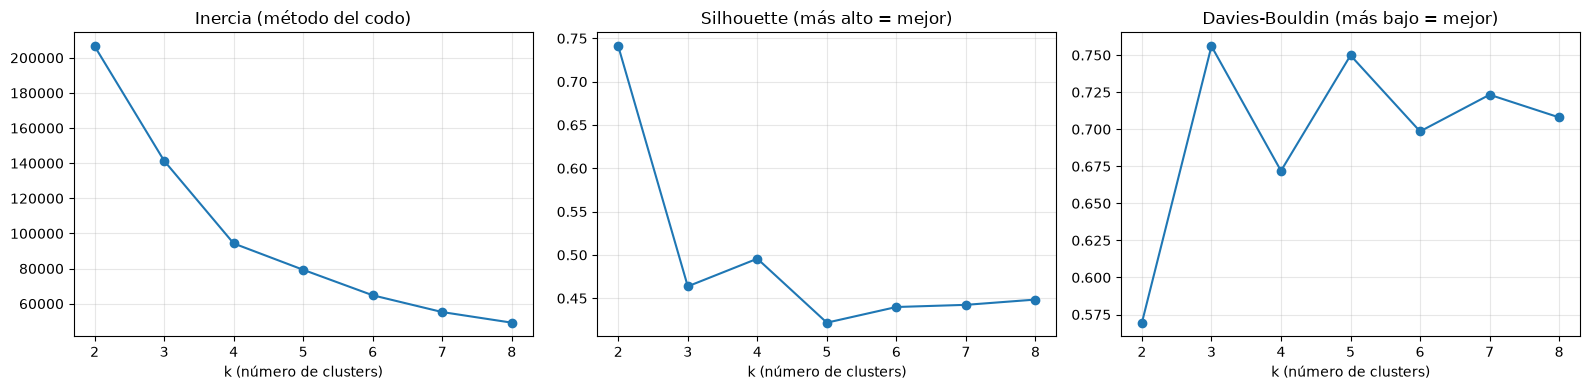

Mejor k por silhouette: 2
Mejor k por Davies-Bouldin: 2


In [5]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
titulos = {
    "inercia": "Inercia (método del codo)",
    "silhouette": "Silhouette (más alto = mejor)",
    "davies_bouldin": "Davies-Bouldin (más bajo = mejor)",
}
for eje, (columna, titulo) in zip(ejes, titulos.items()):
    eje.plot(tabla_k.index, tabla_k[columna], marker="o")
    eje.set_title(titulo)
    eje.set_xlabel("k (número de clusters)")
    eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Mejor k por silhouette:", tabla_k["silhouette"].idxmax())
print("Mejor k por Davies-Bouldin:", tabla_k["davies_bouldin"].idxmin())

## 3. Elección de k

- **Silhouette** es máximo en k = 2 (≈ 0.74) y tiene un segundo pico en k = 4 (≈ 0.50).
- **Davies-Bouldin** es mínimo en k = 2 (≈ 0.57) y tiene un mínimo local en k = 4 (≈ 0.67).
- En la **curva de inercia** la caída es fuerte hasta k = 4 y a partir de ahí se aplana: el codo está en k = 4.

Se elige **k = 4**. Aunque k = 2 obtiene las mejores métricas, solo separa un grupo pequeño de
clientes atípicos del resto, lo que no sirve para diseñar acciones de negocio. k = 4 coincide con
el codo y con los óptimos locales de silhouette y Davies-Bouldin, y produce segmentos
diferenciados e interpretables (ver perfil en la sección 5).

In [11]:
K_ELEGIDO = 4  # ← cambiar según la justificación de la celda anterior

pipeline = segment.entrenar_pipeline_clustering(X, n_clusters=K_ELEGIDO, random_state=SEMILLA)
rfm["segmento"] = pipeline.predict(X)
X_escalado = pipeline.named_steps["escalador"].transform(X)

metricas = segment.evaluar_clustering(
    X_escalado[idx_muestra], rfm["segmento"].to_numpy()[idx_muestra]
)
print(metricas)
rfm["segmento"].value_counts().sort_index()

{'silhouette': 0.49566085016243633, 'davies_bouldin': 0.6719292445718908}


segmento
0    51886
1    38378
2     2883
3     2273
Name: count, dtype: int64

## 4. Visualización en 2D con PCA

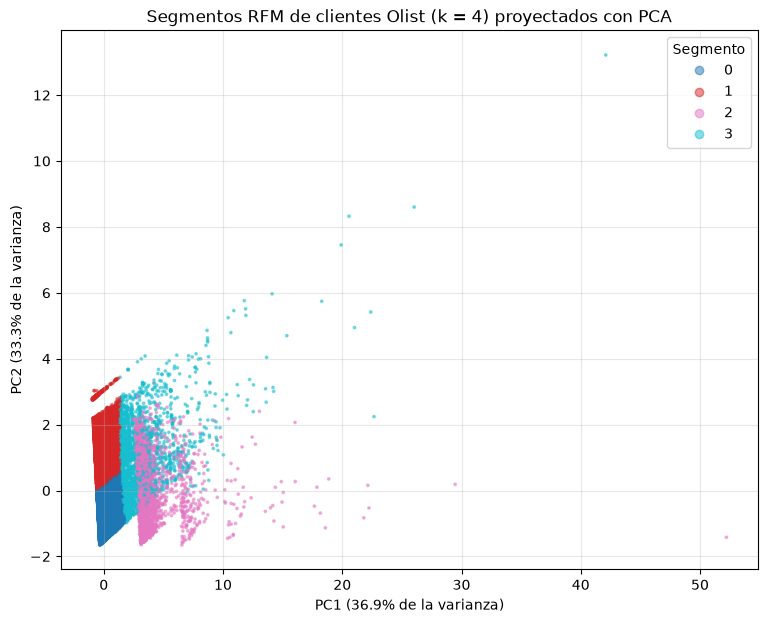

In [7]:
pca = PCA(n_components=2, random_state=SEMILLA)
X_2d = pca.fit_transform(X_escalado)

fig, eje = plt.subplots(figsize=(9, 7))
dispersion = eje.scatter(X_2d[:, 0], X_2d[:, 1], c=rfm["segmento"], cmap="tab10", s=3, alpha=0.5)
eje.legend(*dispersion.legend_elements(), title="Segmento")
eje.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} de la varianza)")
eje.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} de la varianza)")
eje.set_title(f"Segmentos RFM de clientes Olist (k = {K_ELEGIDO}) proyectados con PCA")
eje.grid(alpha=0.3)
plt.show()

## 5. Perfil de los segmentos

In [8]:
perfil = segment.perfilar_segmentos(
    rfm, columna_segmento="segmento", columnas_perfil=["recencia", "frecuencia", "monto"]
)
perfil["pct_clientes"] = (perfil["n_clientes"] / perfil["n_clientes"].sum() * 100).round(2)

DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
perfil.to_csv(DATA_PROCESSED / "clientes_segmentados.csv")
perfil.round(2)

,recencia,frecuencia,monto,n_clientes,pct_clientes
segmento,,,,,
0,133.52,1.00,113.60,51886,54.38
1,393.69,1.00,114.48,38378,40.22
2,226.18,2.11,243.05,2883,3.02
3,244.35,1.01,1145.31,2273,2.38


**Nombre y acción de negocio por segmento**

| Segmento | Nombre propuesto | Perfil | Acción de negocio |
|---|---|---|---|
| 0 | Nuevos recientes | Compraron hace ~4 meses, una sola vez, ticket normal (~R$114). 54 % de los clientes. | Campaña para lograr la **segunda compra**: cupón con vencimiento corto y recomendaciones según su primera compra. |
| 1 | Dormidos / perdidos | Última compra hace más de un año, una sola vez, ticket normal. 40 % de los clientes. | **Reactivación de bajo costo** (email con descuento agresivo). Si no responden, sacarlos de campañas pagas para no gastar presupuesto. |
| 2 | Recurrentes | Los únicos que repiten (≈2 pedidos), con el doble de gasto total (~R$243). 3 % de los clientes. | **Programa de fidelización**: puntos, envío gratis y acceso anticipado a promociones. Son la base para medir retención. |
| 3 | Alto valor | Una compra, pero de ~R$1.145 (10 veces el promedio). 2,4 % de los clientes. | **Atención VIP**: seguimiento posventa, venta cruzada de productos premium y garantía extendida para convertirlos en recurrentes. |

## 6. Anomalías con DBSCAN (pregunta 9.4)

DBSCAN sobre el mismo espacio RFM escalado. Los puntos con etiqueta `-1` no pertenecen a ninguna zona densa: son los candidatos a anomalía.

DBSCAN guarda en memoria los vecinos de cada punto; con ~95 mil clientes muy concentrados (casi todos con frecuencia 1) necesitaría más de 10 GB de RAM. Por eso se corre sobre una muestra aleatoria fija de 20.000 clientes.

In [9]:
idx_dbscan = np.random.default_rng(SEMILLA).choice(len(X), size=min(20_000, len(X)), replace=False)
muestra_dbscan = rfm.iloc[idx_dbscan]

dbscan = DBSCAN(eps=0.5, min_samples=10)
etiquetas_dbscan = dbscan.fit_predict(X_escalado[idx_dbscan])
es_anomalia = etiquetas_dbscan == -1

print(
    f"Anomalías en la muestra: {es_anomalia.sum():,} de {len(idx_dbscan):,} "
    f"({es_anomalia.mean():.2%}); proyectado al total ≈ {es_anomalia.mean() * len(X):,.0f}"
)
muestra_dbscan.loc[es_anomalia, ["recencia", "frecuencia", "monto"]].describe().round(2)

Anomalías en la muestra: 164 de 20,000 (0.82%); proyectado al total ≈ 782


,recencia,frecuencia,monto
count,164.00,164.00,164.00
mean,264.82,1.80,1499.67
std,181.75,1.09,1054.22
min,6.00,1.00,30.70
25%,121.50,1.00,700.15
50%,235.50,1.00,1524.45
75%,375.25,2.00,1997.50
max,699.00,7.00,7160.00


In [10]:
# Algunos ejemplos de clientes anómalos, ordenados por monto
muestra_dbscan.loc[es_anomalia].sort_values("monto", ascending=False).head(10)

,customer_unique_id,recencia,frecuencia,monto,segmento
44139,763c8b1c9c68a0229c42c9fc6f662b93,50,1,7160.00,3
82230,dc4802a71eae9be1dd28f5d788ceb526,568,1,6735.00,3
93341,fa562ef24d41361e476e748681810e1e,158,1,4099.99,3
422,011875f0176909c5cf0b14a9138bb691,534,1,3999.90,3
35328,5e713be0853d8986528d7869a0811d2b,576,1,3980.00,3
70304,bc5e25094a7d51b6aee35236572e64f4,220,1,3690.00,3
33622,59d66d72939bc9497e19d89c61a96d5f,389,2,3459.00,3
16534,2c3b08cf3584d8c0a81d9618a73aa219,147,1,3399.99,3
31363,53fb3435773a4690e56010b169ee2820,206,1,3099.90,3
76942,ce3fe361f9e68bf0a813baaae1334d01,19,1,3099.00,3
